In [31]:
import pandas as pd
import numpy as np
import seaborn as sns

# How to detect Multicollinearity

1) Correlation

In [20]:
df = pd.read_csv('https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv')

df.drop(columns = ["Unnamed: 0"], inplace = True)

df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


<Axes: >

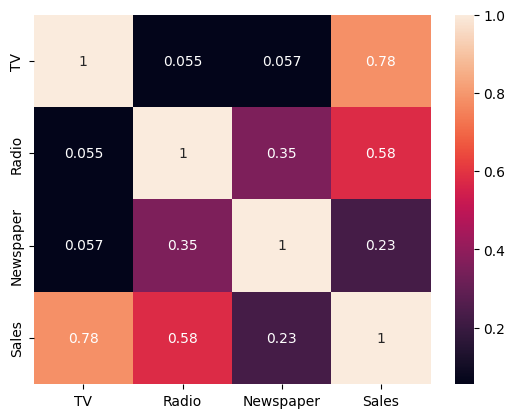

In [21]:
sns.heatmap(df.corr(), annot = True)

# It is found that, correlatiion>=80, are problematic.

# Variance Inflation Factor

* If VIF>=10 for any feature (This condition can be changed based on the data and the problem we are trying to solve), means that feature has high correlation with the other features combined.
* In other words, that feature is **highly explained** by the other features.
* So it is good to remove such feature.

In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = []

for i in range(3):
    vif_ = variance_inflation_factor(df.iloc[:, 0:3], i)
    vif.append(vif_)

print(vif)

[2.486771835198193, 3.2854621001628947, 3.0552445106573853]


In [28]:
pd.DataFrame(
    data = {'vif': vif},
    index = df.columns[0:3]
).T

,TV,Radio,Newspaper
vif,2.486772,3.285462,3.055245


# 3) Condition Number.
* This gives a single value which says if there exists a multicolinearity in the data.
* It tells us how much effort is required to calculate inverse of the matrix.
* If condition number >=30, it is problamatic and can be considered as multicollinearity exists.

In [39]:
# Consider below features
arr = np.array(
    [
        [2, 3],
        [4, 5]
    ]
)

condition_number = np.linalg.cond(arr)

print(f"""
{'-'*10} Array  {'-'*10}
{arr}
{'-'*10} Condition Number  {'-'*10}
{condition_number}
""")


---------- Array  ----------
[[2 3]
 [4 5]]
---------- Condition Number  ----------
26.9629120178363

